# 04-2. 결빙 분류: 고전 ML 기법 비교

04(결빙 발생 분류)의 2장. 04-1의 후보 외에 다른 고전 머신러닝 기법, MLP 구조, 앙상블을 같은 조건(결빙관련 라벨, 같은 변수,
지점 단위 7묶음 교차검증, 일별 F1이 가장 높은 임계값)으로 비교한다. 최종 후보에 넣지 않는 참고용 비교이다.
추가 자료(ERA5-Land 강수·강설)를 더했을 때의 기여도 같은 조건으로 잰다 (2-3).

04 구성: 04-1 Ice 라벨·후보 모델·교차검증(0~1장) · **04-2 고전 ML 비교(2장)** · 04-3 검증 지점 평가·저장(3~5장)

- 입력: 02-2의 지점 변수, 03-3의 추정 노면온도, 04-1의 교차검증 확률·설정 (`icing_oof.parquet`, `icing_cv.json`),
  02-3의 ERA5-Land (`era5_10min.parquet`)
- 출력: 비교 결과 표 (`data/results/icing_model_comparison.csv`, `icing_mlp_architectures.csv`, `icing_ensembles.csv`, `icing_era5_ablation.csv`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import itertools
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from cycler import cycler
from joblib import Parallel, delayed
from matplotlib import font_manager
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점 (04-1과 같음)
sf["date"] = sf["time"].dt.normalize()
cv = json.load(open(config.PROCESSED_DIR / "icing_cv.json", encoding="utf-8"))  # 04-1에서 정한 설정
CLS_FEATURES, folds, FINAL, INTERPRET = cv["features"], cv["folds"], cv["final"], cv["interpret"]
sf["related"] = sf["state"].isin(cv["related_states"]).astype("float32").where(sf["state"].notna())
train_all = sf[~sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
stns = sorted(train_all["stn"].unique())

# 04-1의 학습 지점 교차검증 확률 (후보 3개)
oof_prob = pd.read_parquet(config.PROCESSED_DIR / "icing_oof.parquet")
assert oof_prob["stn"].equals(train_all["stn"]) and oof_prob["time"].equals(train_all["time"])
oof_prob = oof_prob.drop(columns=["stn", "time"])
print(f"학습 지점 {len(stns)}곳, 최종 모델: {FINAL}, 해석용 모델: {INTERPRET}")

학습 지점 14곳, 최종 모델: LightGBM(결빙관련 라벨), 해석용 모델: 로지스틱 회귀(결빙관련 라벨)


## 2. 고전 ML 기법 비교

"LightGBM이 최선인가"를 확인하려고 다른 고전 머신러닝 기법도 **같은 조건**(결빙관련 라벨, 같은 26개 변수, 양성 가중치 5,
지점 단위 7묶음 교차검증, 일별 F1이 가장 높은 임계값)으로 비교한다. 이 절의 기법들은 최종 후보에 넣지 않는 참고용 비교이다.

| 기법 | 설정 |
|------|------|
| XGBoost | 깊이 4, 400회, 학습률 0.03 (LightGBM과 같은 부스팅 계열) |
| 스플라인 로지스틱 (GAM 근사) | 변수별 3차 스플라인(매듭 5개)을 만든 뒤 로지스틱 (C=0.05). 변수마다 비선형 효과를 허용 |
| Random Forest | 200그루, 잎 최소 50행, 그루마다 30% 표본 |
| Extra Trees | 200그루, 잎 최소 50행, 무작위 분할 |
| MLP | 은닉층 32-16 (ReLU), L2 1e-3, 조기 종료. 표준화 입력 |

In [4]:
POS_W = 5


def imputed(*steps):
    return make_pipeline(SimpleImputer(strategy="median"), *steps)


OTHER_MODELS = {
    "XGBoost": lambda: xgb.XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=50,
                                         subsample=0.7, colsample_bytree=0.7, reg_lambda=5.0, scale_pos_weight=POS_W,
                                         tree_method="hist", n_jobs=4, random_state=SEED),
    "스플라인 로지스틱(GAM)": lambda: imputed(SplineTransformer(n_knots=5, extrapolation="linear"), StandardScaler(),
                                      LogisticRegression(C=0.05, class_weight={0: 1, 1: POS_W}, max_iter=3000)),
    "Random Forest": lambda: imputed(RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features="sqrt",
                                                            max_samples=0.3, class_weight={0: 1, 1: POS_W},
                                                            n_jobs=-1, random_state=SEED)),
    "Extra Trees": lambda: imputed(ExtraTreesClassifier(n_estimators=200, min_samples_leaf=50, max_features=0.5,
                                                        max_samples=0.3, bootstrap=True, class_weight={0: 1, 1: POS_W},
                                                        n_jobs=-1, random_state=SEED)),
    "MLP(32-16)": lambda: imputed(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3,
                                                                  early_stopping=True, max_iter=80, batch_size=512,
                                                                  random_state=SEED)),
}


def fit_related(make, df):
    """결빙관련 라벨로 학습한다. MLP는 class_weight가 없어 양성 표본 가중치로 같은 효과를 준다."""
    d = df.dropna(subset=["related"])
    y = d["related"].astype(int)
    m = make()
    if hasattr(m, "steps") and isinstance(m[-1], MLPClassifier):
        return m.fit(d[CLS_FEATURES], y, mlpclassifier__sample_weight=np.where(y == 1, POS_W, 1.0))
    return m.fit(d[CLS_FEATURES], y)


def oof_related(make):
    prob = np.full(len(train_all), np.nan)
    for val_stns in folds:
        va = train_all["stn"].isin(val_stns).to_numpy()
        prob[va] = fit_related(make, train_all[~va]).predict_proba(train_all.loc[va, CLS_FEATURES])[:, 1]
    return prob


cmp_prob = pd.DataFrame({"LightGBM(결빙관련 라벨)": oof_prob["LightGBM(결빙관련 라벨)"],
                         "로지스틱 회귀(결빙관련 라벨)": oof_prob["로지스틱 회귀(결빙관련 라벨)"]})
cmp_time = {}
for name, make in OTHER_MODELS.items():
    t0 = time.time()
    cmp_prob[name] = oof_related(make)
    cmp_time[name] = time.time() - t0
    print(f"{name}: {cmp_time[name]:.0f}s")

XGBoost: 26s


스플라인 로지스틱(GAM): 97s


Random Forest: 86s


Extra Trees: 62s


MLP(32-16): 142s


모델 간 일별 F1 차이가 우연인지 보려고 **날짜 단위 부트스트랩**(1,000회)으로 차이의 95% 구간을 구한다.
같은 날의 여러 지점은 같은 기상을 겪으므로 날짜를 통째로 다시 뽑는다. 계산을 빠르게 하려고 일별 F1을 지점-날 단위 배열로 미리 만든다.

In [5]:
lab_rows = train_all["ice"].notna().to_numpy()
stn_pos = {s: i for i, s in enumerate(stns)}
day_key, _ = pd.factorize(train_all.loc[lab_rows, "stn"].astype(str) + "_"
                          + train_all.loc[lab_rows, "time"].dt.strftime("%Y%m%d"))
day_stn = np.zeros(day_key.max() + 1, int)
day_stn[day_key] = train_all.loc[lab_rows, "stn"].map(stn_pos).to_numpy()
day_date = np.zeros(day_key.max() + 1, int)
day_date[day_key] = pd.factorize(train_all.loc[lab_rows, "time"].dt.normalize())[0]
y_lab = train_all.loc[lab_rows, "ice"].astype(int).to_numpy()


def day_f1(pred):
    """지점-날별 (F1, 평가 여부). 평가 = 그날 실제·예측 결빙이 하나라도 있음 (빈 날 제외 방식)."""
    p = np.asarray(pred)[lab_rows].astype(int)
    tp = np.bincount(day_key, y_lab & p)
    fp = np.bincount(day_key, (1 - y_lab) & p)
    fn = np.bincount(day_key, y_lab & (1 - p))
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0), den > 0


def mean_daily_f1(f1, ev, station_idx=None, date_w=None):
    """지점별 평가일 평균 → 지점 평균 (daily_f1과 같은 값). date_w: 날짜별 부트스트랩 가중치."""
    w = ev * (1.0 if date_w is None else date_w[day_date])
    s_sum = np.bincount(day_stn, f1 * w, len(stns))
    s_n = np.bincount(day_stn, w, len(stns))
    per = np.where(s_n > 0, s_sum / np.where(s_n > 0, s_n, 1), np.nan)
    return np.nanmean(per if station_idx is None else per[station_idx])


def best_thr_fast(score_vec, station_idx=None):
    cands = np.unique(np.quantile(score_vec[~np.isnan(score_vec)], (0.95, 0.98, 0.99, 0.995, 0.998, 0.999, 0.9995, 0.9998)))
    vals = [mean_daily_f1(*day_f1(score_vec >= t), station_idx) for t in cands]
    return cands[int(np.argmax(vals))], max(vals)


related_ok = train_all["related"].notna().to_numpy()
rows = []
day_scores = {}
for name in cmp_prob:
    prob = cmp_prob[name].to_numpy()
    thr, f1 = best_thr_fast(prob)
    day_scores[name] = day_f1(prob >= thr)
    rows.append({"방법": name, "AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
                 "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok]),
                 "일별 F1 (빈 날 제외)": f1, "Ice 포착률(10분)": (prob >= thr)[lab_rows][y_lab == 1].mean(),
                 "결빙 판정 비율": (prob >= thr).mean(), "학습 시간(s)": cmp_time.get(name, np.nan)})
cmp_table = pd.DataFrame(rows).set_index("방법")

n_dates = day_date.max() + 1
rng = np.random.default_rng(SEED)
boot_w = np.stack([np.bincount(rng.integers(0, n_dates, n_dates), minlength=n_dates) for _ in range(1000)])
ref = FINAL if FINAL in cmp_prob else "LightGBM(결빙관련 라벨)"
ref_boot = np.array([mean_daily_f1(*day_scores[ref], date_w=w) for w in boot_w])
for name in cmp_prob:
    diff = np.array([mean_daily_f1(*day_scores[name], date_w=w) for w in boot_w]) - ref_boot
    cmp_table.loc[name, f"{ref} 대비 차이"] = cmp_table.loc[name, "일별 F1 (빈 날 제외)"] - cmp_table.loc[ref, "일별 F1 (빈 날 제외)"]
    cmp_table.loc[name, "95% 구간"] = f"[{np.quantile(diff, 0.025):+.4f}, {np.quantile(diff, 0.975):+.4f}]"
print("참고: Ice 비율(무작위 예측의 AP) =", round(y_lab.mean(), 5))
cmp_table.sort_values("일별 F1 (빈 날 제외)", ascending=False).round(4)

참고: Ice 비율(무작위 예측의 AP) = 0.0005


,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),Ice 포착률(10분),결빙 판정 비율,학습 시간(s),LightGBM(결빙관련 라벨) 대비 차이,95% 구간
방법,,,,,,,,
로지스틱 회귀(결빙관련 라벨),0.0087,0.4865,0.0317,0.2259,0.010,NaN,0.0056,"[-0.0109, +0.0266]"
스플라인 로지스틱(GAM),0.0106,0.4762,0.0308,0.0795,0.002,97.4987,0.0048,"[-0.0135, +0.0343]"
Random Forest,0.0089,0.4989,0.0267,0.2427,0.010,85.6056,0.0007,"[-0.0108, +0.0110]"
LightGBM(결빙관련 라벨),0.0095,0.4690,0.0260,0.1506,0.005,NaN,0.0000,"[+0.0000, +0.0000]"
XGBoost,0.0106,0.4927,0.0250,0.2636,0.010,26.3184,-0.0011,"[-0.0107, +0.0089]"
Extra Trees,0.0088,0.5025,0.0246,0.2259,0.010,61.7088,-0.0014,"[-0.0143, +0.0124]"
MLP(32-16),0.0102,0.4492,0.0194,0.3013,0.010,142.2321,-0.0066,"[-0.0204, +0.0060]"


- 7개 기법의 일별 F1은 0.019~0.032, AP(Ice)는 0.0087~0.0106로 모두 비슷하다 (무작위 예측 AP 0.0005의 약 20배).
- 최종 모델(LightGBM) 대비 차이의 95% 구간이 모두 0을 포함한다.
  예: 로지스틱 +0.006 [-0.011, +0.027], XGBoost -0.001 [-0.011, +0.009], Random Forest +0.001 [-0.011, +0.011],
  MLP -0.007 [-0.020, +0.006]. **어느 기법이 낫다고 말할 수 없다.**
- 지표마다 1위도 다르다. 일별 F1은 로지스틱, AP(Ice)는 XGBoost·스플라인 로지스틱, AP(결빙관련)는 Extra Trees·Random Forest가 가장 높다.
- 성능을 정하는 것은 기법보다 라벨이다. 0절에서 본 것처럼 실제 노면상태를 알아도 일별 F1의 상한이 0.1에 못 미친다.

### 2-1. MLP 구조 실험

신경망은 층을 어떻게 쌓느냐에 따라 결과가 달라질 수 있으므로, 은닉층의 **너비**(16~256), **깊이**(1~4층), **L2 규제**, **활성화 함수**,
**여러 시드 평균**을 바꿔 가며 같은 교차검증으로 비교한다. 모두 표준화 입력, Adam, 미니배치 512, 학습 자료 10%로 조기 종료한다.

In [6]:
MLP_ARCHS = [
    ("1층 16", (16,), {}), ("1층 64", (64,), {}), ("1층 256", (256,), {}),
    ("2층 32-16", (32, 16), {}), ("2층 64-64", (64, 64), {}), ("2층 256-256", (256, 256), {}),
    ("3층 128-64-32", (128, 64, 32), {}), ("4층 256-128-64-32", (256, 128, 64, 32), {}),
    ("2층 32-16, L2 0.1", (32, 16), {"alpha": 0.1}), ("2층 32-16, L2 1", (32, 16), {"alpha": 1.0}),
    ("2층 32-16, tanh", (32, 16), {"activation": "tanh"}),
    ("2층 32-16, 시드 5개 평균", (32, 16), {"seeds": 5}),
]


def mlp_fold(data, hidden, opt, val_stns, seed):
    """한 묶음의 MLP 학습·예측 (7묶음 병렬, 묶음당 BLAS 2스레드). 반환: (검증 행 마스크, 확률)."""
    warnings.filterwarnings("ignore", category=UserWarning)
    with threadpool_limits(2):
        va = data["stn"].isin(val_stns).to_numpy()
        make = lambda: imputed(StandardScaler(), MLPClassifier(  # noqa: E731
            hidden_layer_sizes=hidden, alpha=opt.get("alpha", 1e-3), activation=opt.get("activation", "relu"),
            early_stopping=True, max_iter=80, batch_size=512, random_state=seed))
        return va, fit_related(make, data[~va]).predict_proba(data.loc[va, CLS_FEATURES])[:, 1]


mlp_rows, mlp_prob = [], {}
mlp_data = train_all[["stn", "related"] + CLS_FEATURES]
for name, hidden, opt in MLP_ARCHS:
    t0 = time.time()
    outs = Parallel(n_jobs=7)(delayed(mlp_fold)(mlp_data, hidden, opt, v, SEED + k)
                              for k in range(opt.get("seeds", 1)) for v in folds)
    acc, cnt = np.zeros(len(train_all)), np.zeros(len(train_all))
    for va, p in outs:
        acc[va] += p
        cnt[va] += 1
    prob = acc / np.maximum(cnt, 1)
    mlp_prob[name] = prob
    n_params = sum(a * b for a, b in zip((len(CLS_FEATURES),) + hidden, hidden + (1,))) + sum(hidden) + 1
    mlp_rows.append({"구조": name, "층 수": len(hidden), "매개변수 수": n_params,
                     "AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
                     "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok]),
                     "일별 F1 (빈 날 제외)": best_thr_fast(prob)[1], "학습 시간(s)": time.time() - t0})
    print(f"{name}: {time.time() - t0:.0f}s")
mlp_table = pd.DataFrame(mlp_rows).set_index("구조")
mlp_table.round(4)

1층 16: 34s


1층 64: 48s


1층 256: 126s


2층 32-16: 49s


2층 64-64: 75s


2층 256-256: 343s


... (3 outputs left out)

2층 32-16, L2 1: 26s


2층 32-16, tanh: 39s


2층 32-16, 시드 5개 평균: 219s


,층 수,매개변수 수,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),학습 시간(s)
구조,,,,,,
1층 16,1,449,0.0094,0.4638,0.0182,34.4965
1층 64,1,1793,0.0099,0.4690,0.0177,47.6255
1층 256,1,7169,0.0098,0.4371,0.0212,126.0433
2층 32-16,2,1409,0.0102,0.4492,0.0194,49.4134
2층 64-64,2,5953,0.0087,0.4212,0.0236,74.6157
2층 256-256,2,72961,0.0083,0.3826,0.0171,342.7868
3층 128-64-32,3,13825,0.0075,0.4050,0.0186,112.1733
4층 256-128-64-32,4,50177,0.0087,0.4110,0.0235,232.6358
"2층 32-16, L2 0.1",2,1409,0.0089,0.4740,0.0253,47.0535


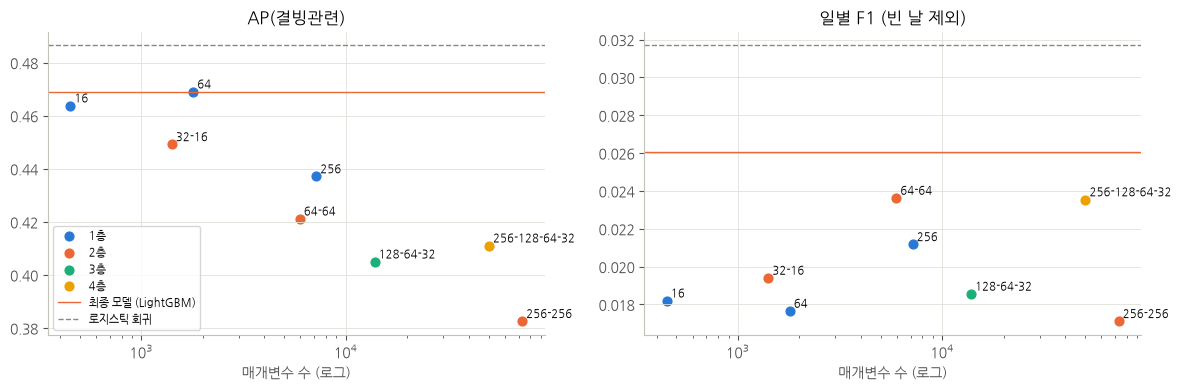

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plain = mlp_table[~mlp_table.index.str.contains(",")]
for ax, col in zip(axes, ["AP(결빙관련)", "일별 F1 (빈 날 제외)"]):
    for depth, g in plain.groupby("층 수"):
        ax.scatter(g["매개변수 수"], g[col], s=40, label=f"{depth}층")
        for name, r in g.iterrows():
            ax.annotate(name.split(" ")[1], (r["매개변수 수"], r[col]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axhline(cmp_table.loc[FINAL, col], color="#eb6834", linewidth=1, label="최종 모델 (LightGBM)")
    ax.axhline(cmp_table.loc[INTERPRET, col], color="#898781", linewidth=1, linestyle="--", label="로지스틱 회귀")
    ax.set_xscale("log")
    ax.set_xlabel("매개변수 수 (로그)")
    ax.set_title(col)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

- 노면온도 추정(03-2의 3-2)과 같은 양상이다. 크고 깊을수록 결빙관련 AP가 떨어진다.
  1층 16개 0.464 → 2층 256-256 0.383, 3층 128-64-32 0.405, 4층 256-128-64-32 0.411.
- 가장 좋은 구조는 강한 규제(L2 1)를 건 2층 32-16이다 (AP 0.513, 일별 F1 0.025). 시드 5개를 평균해도 0.449 → 0.486으로 나아진다.
  규제·평균처럼 **분산을 줄이는 쪽만 도움이 된다.**
- 그래도 LightGBM(AP 0.469, 일별 F1 0.026)·로지스틱 회귀(0.487, 0.032)와 같은 수준이다. AP는 조금 높지만 일별 F1은 낮다.
  학습 지점이 14곳뿐이라 신경망의 표현력이 이점이 되지 못한다.

### 2-2. 앙상블 실험

서로 다른 모델의 확률을 합치면 나아지는지 본다. 모델마다 확률의 크기가 다르므로 **순위 평균**(각 모델 확률을 0~1 백분위로 바꿔 평균)을 쓴다.
후보는 위 7개 모델(LightGBM, 로지스틱, XGBoost, 스플라인 로지스틱, RF, Extra Trees, MLP 32-16)의 2~4개 조합 전부이다.

같은 교차검증 결과로 조합을 고르면 고른 과정 자체가 점수를 부풀린다(선택 편향). 그래서 **중첩 교차검증**으로 정직한 점수도 함께 낸다:
7묶음마다 나머지 12개 지점만으로 조합과 임계값을 고르고, 그 묶음 지점에 적용한다.

In [8]:
ENS_POOL = list(cmp_prob.columns)
ranks = cmp_prob.rank(pct=True).to_numpy()
subsets = [c for k in range(1, 5) for c in itertools.combinations(range(len(ENS_POOL)), k)]
sub_score = {c: ranks[:, list(c)].mean(axis=1) for c in subsets}
sub_f1 = {c: best_thr_fast(v)[1] for c, v in sub_score.items()}
ens_top = pd.DataFrame([{"조합": " + ".join(ENS_POOL[i] for i in c), "모델 수": len(c), "일별 F1 (빈 날 제외)": f1,
                         "AP(Ice)": average_precision_score(y_lab, sub_score[c][lab_rows])}
                        for c, f1 in sorted(sub_f1.items(), key=lambda kv: -kv[1])[:10]])
print("조합 크기별 최고 일별 F1 (같은 교차검증으로 고름, 낙관적):",
      {k: round(max(v for c, v in sub_f1.items() if len(c) == k), 4) for k in range(1, 5)})
ens_top.round(4)

조합 크기별 최고 일별 F1 (같은 교차검증으로 고름, 낙관적): {1: np.float64(0.0317), 2: np.float64(0.0305), 3: np.float64(0.0369), 4: np.float64(0.0347)}


,조합,모델 수,일별 F1 (빈 날 제외),AP(Ice)
0,로지스틱 회귀(결빙관련 라벨) + 스플라인 로지스틱(GAM) + MLP(32-16),3,0.0369,0.0103
1,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...,3,0.0365,0.0104
2,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...,4,0.0347,0.0104
3,로지스틱 회귀(결빙관련 라벨) + XGBoost + 스플라인 로지스틱(GAM) + ...,4,0.0317,0.0105
4,로지스틱 회귀(결빙관련 라벨),1,0.0317,0.0087
5,스플라인 로지스틱(GAM),1,0.0308,0.0106
6,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...,4,0.0306,0.0101
7,LightGBM(결빙관련 라벨) + Random Forest + Extra Tree...,4,0.0305,0.0096
8,Random Forest + MLP(32-16),2,0.0305,0.0095
9,XGBoost + Random Forest + Extra Trees + MLP(32...,4,0.0304,0.0096


In [9]:
def nested_daily_f1(candidates):
    """묶음마다 나머지 지점으로 조합·임계값을 고르고 묶음에 적용한 예측의 일별 F1."""
    pred, picks = np.zeros(len(train_all), bool), []
    for val_stns in folds:
        tr_idx = np.array([stn_pos[s] for s in stns if s not in val_stns])
        best = max(candidates, key=lambda c: best_thr_fast(sub_score[c], tr_idx)[1])
        thr, _ = best_thr_fast(sub_score[best], tr_idx)
        va = train_all["stn"].isin(val_stns).to_numpy()
        pred[va] = sub_score[best][va] >= thr
        picks.append(" + ".join(ENS_POOL[i] for i in best))
    return mean_daily_f1(*day_f1(pred)), pd.Series(picks).value_counts().to_dict()


def fixed(*names):
    return [tuple(sorted(ENS_POOL.index(n) for n in names))]


NESTED = {
    "LightGBM 고정 (최종 모델)": fixed("LightGBM(결빙관련 라벨)"),
    "로지스틱 고정": fixed("로지스틱 회귀(결빙관련 라벨)"),
    "LightGBM + 로지스틱 순위 평균 고정": fixed("LightGBM(결빙관련 라벨)", "로지스틱 회귀(결빙관련 라벨)"),
    "7개 전체 순위 평균 고정": [tuple(range(len(ENS_POOL)))],
    "단일 모델 선택 (중첩)": [c for c in subsets if len(c) == 1],
    "조합 선택 2~4개 (중첩)": [c for c in subsets if len(c) >= 2],
}
for c in NESTED["7개 전체 순위 평균 고정"]:
    sub_score[c] = ranks.mean(axis=1)
nested_rows = []
for name, cand in NESTED.items():
    f1, picks = nested_daily_f1(cand)
    nested_rows.append({"방법": name, "일별 F1 (빈 날 제외, 정직)": f1,
                        "묶음별 선택": "; ".join(f"{k} ({v}회)" for k, v in picks.items()) if len(cand) > 1 else ""})
pd.DataFrame(nested_rows).set_index("방법").round(4)

,"일별 F1 (빈 날 제외, 정직)",묶음별 선택
방법,,
LightGBM 고정 (최종 모델),0.0260,
로지스틱 고정,0.0317,
LightGBM + 로지스틱 순위 평균 고정,0.0240,
7개 전체 순위 평균 고정,0.0197,
단일 모델 선택 (중첩),0.0135,로지스틱 회귀(결빙관련 라벨) (3회); 스플라인 로지스틱(GAM) (3회); Ra...
조합 선택 2~4개 (중첩),0.0141,로지스틱 회귀(결빙관련 라벨) + 스플라인 로지스틱(GAM) + MLP(32-16)...


- 같은 교차검증으로 고르면 3개 조합(로지스틱 + 스플라인 로지스틱 + MLP 등)이 0.037로 가장 높아 보인다.
  하지만 고르는 과정까지 중첩 교차검증으로 평가하면 0.014로 크게 낮아진다. 단일 모델을 고르는 경우(0.014)도 마찬가지이다.
  묶음마다 고르는 조합이 바뀌고, 일별 F1이 몇 날의 결과에 크게 흔들리기 때문이다 (선택 편향).
- 고정 조합도 나아지지 않는다: LightGBM + 로지스틱 0.024, 7개 전체 0.020 (LightGBM 단독 0.026, 로지스틱 단독 0.032).
- "고정" 행은 임계값을 14개 지점 전체로 고른 것이라 중첩 행보다 조금 낙관적이다. 같은 조건에서 정직하게 단일 모델을 고른 점수는 0.014이다.
- **앙상블은 쓰지 않는다.**

### 2-3. 추가 자료 기여: ERA5-Land 강수·강설

이 지역 Ice의 81%는 강수 중이거나 강수 직후에 나왔다 (01-6의 13장). 그런데 지금 변수의 수분 정보는 AWS 강수 감지·강수량
(`rain`, `pr60`, `pr12h`, `rain_hrs12h`, `hrs_since_rain`)과 ASOS 적설(`snow`)뿐이라, **지금 내리는 것이 눈인지 비인지**를 나타내는 변수가 없다.
ERA5-Land(02-3)는 격자(약 9km)마다 강수와 강설(물 환산)을 나누어 주므로, 지난 3시간 강수 합·강설 합·강설 비율 3개를 더해 기여를 잰다.

- 모델: 04-1의 두 후보(LightGBM, 로지스틱 회귀, 결빙관련 라벨)를 같은 설정으로 다시 학습한다. 기준은 04-1의 교차검증 확률이다.
- 지표: AP(Ice), AP(결빙관련), 일별 F1(빈 날 제외, 임계값은 같은 교차검증으로 고름)과 일별 F1 차이의 날짜 단위 부트스트랩 95% 구간 (2절과 같음)
- 검증 지점은 쓰지 않는다. RWIS 관측은 ERA5에 동화되지 않으므로 학습 지점의 라벨이 입력에 섞이지도 않는다.

In [10]:
import lightgbm as lgb

LGB_PARAMS = dict(objective="binary", learning_rate=0.03, n_estimators=400, num_leaves=15, min_child_samples=200,
                  subsample=0.7, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
                  random_state=SEED, n_jobs=-1, verbose=-1)  # 04-1과 같은 설정
E5_MODELS = {
    "LightGBM(결빙관련 라벨)": lambda: lgb.LGBMClassifier(**LGB_PARAMS, scale_pos_weight=POS_W),
    "로지스틱 회귀(결빙관련 라벨)": lambda: imputed(StandardScaler(),
                                          LogisticRegression(C=0.1, class_weight={0: 1, 1: POS_W}, max_iter=2000)),
}
ERA5_FEATURES = ["era5_tp3h", "era5_sf3h", "era5_snowfrac3h"]
era5 = pd.read_parquet(config.PROCESSED_DIR / "era5_10min.parquet", columns=["stn", "time", "tp3h", "sf3h", "snowfrac3h"])
e5 = train_all[["stn", "time"]].merge(era5, on=["stn", "time"], how="left", validate="one_to_one")
train_e5 = train_all.assign(**{f"era5_{c}": e5[c].to_numpy() for c in ["tp3h", "sf3h", "snowfrac3h"]})
print("ERA5가 빈 행:", int(train_e5[ERA5_FEATURES].isna().any(axis=1).sum()))

e5_prob, e5_share = {}, {}
for name, make in E5_MODELS.items():
    t0 = time.time()
    prob, share = np.full(len(train_e5), np.nan), []
    for val_stns in folds:
        va = train_e5["stn"].isin(val_stns).to_numpy()
        d = train_e5[~va].dropna(subset=["related"])
        m = make().fit(d[CLS_FEATURES + ERA5_FEATURES], d["related"].astype(int))
        prob[va] = m.predict_proba(train_e5.loc[va, CLS_FEATURES + ERA5_FEATURES])[:, 1]
        if name.startswith("LightGBM"):
            gain = m.booster_.feature_importance("gain")
            share.append(gain[-3:] / gain.sum())
        else:
            share.append(m[-1].coef_[0][-3:])
    e5_prob[name], e5_share[name] = prob, np.mean(share, axis=0)
    print(f"{name} + ERA5: {time.time() - t0:.0f}s")
print(pd.DataFrame({"LightGBM 정보 이득 중 몫": e5_share["LightGBM(결빙관련 라벨)"],
                    "로지스틱 표준화 계수": e5_share["로지스틱 회귀(결빙관련 라벨)"]},
                   index=["3시간 강수", "3시간 강설", "강설 비율"]).round(3).to_string())  # 7묶음 평균


def ap_scores(prob):
    return {"AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
            "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok])}


e5_rows = []
for name, prob in e5_prob.items():
    thr, f1 = best_thr_fast(prob)
    e5_days = day_f1(prob >= thr)
    diff = np.array([mean_daily_f1(*e5_days, date_w=w) - mean_daily_f1(*day_scores[name], date_w=w) for w in boot_w])
    base_f1 = cmp_table.loc[name, "일별 F1 (빈 날 제외)"]
    e5_rows.append({"모델": name, "변수": "04-1 변수 26개", **ap_scores(cmp_prob[name].to_numpy()),
                    "일별 F1 (빈 날 제외)": base_f1})
    e5_rows.append({"모델": name, "변수": "+ ERA5 강수·강설 3개", **ap_scores(prob), "일별 F1 (빈 날 제외)": f1,
                    "일별 F1 차이": f1 - base_f1,
                    "95% 구간": f"[{np.quantile(diff, 0.025):+.4f}, {np.quantile(diff, 0.975):+.4f}]"})
era5_table = pd.DataFrame(e5_rows).set_index(["모델", "변수"])
era5_table.round(4)

ERA5가 빈 행: 0


LightGBM(결빙관련 라벨) + ERA5: 32s


로지스틱 회귀(결빙관련 라벨) + ERA5: 40s
        LightGBM 정보 이득 중 몫  로지스틱 표준화 계수
3시간 강수               0.004       -0.944
3시간 강설               0.177        0.336
강설 비율                0.216        0.160


AP(Ice)  AP(결빙관련)  일별 F1 (빈 날 제외)  일별 F1 차이              95% 구간
모델                변수                                                                              
LightGBM(결빙관련 라벨) 04-1 변수 26개       0.0095    0.4690          0.0260       NaN                 NaN
                  + ERA5 강수·강설 3개   0.0100    0.4723          0.0247   -0.0013  [-0.0134, +0.0096]
로지스틱 회귀(결빙관련 라벨)  04-1 변수 26개       0.0087    0.4865          0.0317       NaN                 NaN
                  + ERA5 강수·강설 3개   0.0091    0.5021          0.0233   -0.0084  [-0.0276, +0.0052]

- **ERA5 강수·강설은 순위 지표(AP)를 조금 올리지만 일별 F1은 올리지 못한다.**
  AP(Ice)·AP(결빙관련)는 LightGBM 0.0095 → 0.0100, 0.469 → 0.472, 로지스틱 0.0087 → 0.0091, 0.487 → 0.502로 조금 높아진다.
  일별 F1은 LightGBM 0.026 → 0.025(차이 95% 구간 [-0.013, +0.010]), 로지스틱 0.032 → 0.023([-0.028, +0.005])이고 구간이 모두 0을 포함한다.
- 모델은 ERA5 변수를 많이 쓴다. LightGBM 정보 이득의 약 40%가 3시간 강설과 강설 비율에서 나오고,
  로지스틱에서는 강설(+0.34)과 강수(-0.94)의 계수 부호가 반대이다. 강설이 같다면 강수가 많을수록(비가 섞일수록) 결빙관련 노면이 줄어든다는 뜻이다.
- 그런데도 점수가 오르지 않는 것은 ASOS 적설, 주변 RWIS의 Snow 비율, AWS 강수 이력이 이미 같은 정보를 대부분 담고 있어서,
  ERA5가 그 자리를 바꿔 쓸 뿐 새 정보를 많이 더하지 못하기 때문으로 보인다.
- **최종 결빙 분류 모델에는 넣지 않는다** (04-1의 26개 변수 유지). ERA5 강설은 05-1의 결빙 영향인자 분석과 05-2의 기상 지표 후보(M3)로 쓴다.

### 2-4. 정리

| 실험 | 결과 | 판단 |
|------|------|------|
| 다른 고전 기법 7종 (2절) | 일별 F1 0.019~0.032, LightGBM과의 차이 95% 구간이 모두 0 포함 | LightGBM이 최선이라고 할 수 없다. 어느 기법도 뚜렷이 낫지 않다 |
| MLP 구조 12가지 (2-1) | 작고 규제가 강할수록 좋다 (최고 AP 0.513) | 신경망의 이점이 없다 |
| 앙상블 (2-2) | 중첩 정직 점수 0.014 (단일 모델 선택 0.014) | 쓰지 않는다 |
| 추가 자료 ERA5-Land 강수·강설 (2-3) | AP 소폭 상승 (결빙관련 AP LightGBM 0.469 → 0.472, 로지스틱 0.487 → 0.502), 일별 F1 차이 95% 구간이 0 포함 | 최종 모델에 넣지 않는다. 05의 영향인자·기상 지표 후보로 쓴다 |

- **최종 모델은 LightGBM(결빙관련 라벨)이고, 로지스틱 회귀는 해석용으로 함께 제시한다** (선택 과정은 1절).
  두 모델의 성능은 교차검증으로 구분되지 않는다. LightGBM은 Ice AP와 검증 지점 성능이 조금 높고,
  로지스틱은 계수로 결빙 요인의 방향을 바로 읽을 수 있어 05의 위험도 해석과 연결하기 쉽다.
- 결빙 분류의 성능을 정하는 것은 기법이 아니라 **라벨**(10분 단위로 깜빡이는 Ice, 제빙제 영향 코드)과 **학습 지점 수**이다.

## 저장

- `data/results/icing_model_comparison.csv`, `icing_mlp_architectures.csv`, `icing_ensembles.csv`: 기법 비교·MLP 구조·앙상블 결과
- `data/results/icing_era5_ablation.csv`: ERA5-Land 강수·강설을 더했을 때의 교차검증 비교 (2-3)

In [11]:
cmp_table.round(4).to_csv(config.RESULT_DIR / "icing_model_comparison.csv", encoding="utf-8-sig")
mlp_table.round(4).to_csv(config.RESULT_DIR / "icing_mlp_architectures.csv", encoding="utf-8-sig")
pd.DataFrame(nested_rows).round(4).to_csv(config.RESULT_DIR / "icing_ensembles.csv", index=False, encoding="utf-8-sig")
era5_table.round(4).to_csv(config.RESULT_DIR / "icing_era5_ablation.csv", encoding="utf-8-sig")
print("저장 완료")

저장 완료
